# RQ06 — características associadas ao desempenho DORA (Issue #67)

Para cada fator × métrica (RQ01 a RQ04 na definição de referência C1), Kruskal-Wallis entre os grupos (Mann-Whitney se houver só dois), correção de Holm sobre todos os p-valores juntos e tamanho de efeito: ε² = H/(n − 1) para o teste global e Cliff's delta entre os grupos extremos, interpretado pela escala de Romano et al. (2006).

**Fatores.** Linguagem principal, quartis de estrelas, quartis de contribuidores e quartis de idade. O tipo de projeto não entra: os 60 repositórios rotulados na amostra-ouro foram sorteados de uma seleção anterior e nenhum deles está na amostra final de 300 (verificado abaixo).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

ANALISE = Path.cwd()
CODE = ANALISE.parent / 'code'
sys.path.insert(0, str(CODE))
from metrics.estatistica import (
    cliffs_delta, comparar_grupos, ic_cliffs_delta, ic_epsilon_quadrado, interpretar_cliffs_delta, quartis,
)

FIGURAS = ANALISE / 'figuras'
TABELAS = ANALISE / 'tabelas'
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

df = pd.read_csv(CODE / 'data' / 'dataset_dora.csv')
ouro = pd.read_csv(ANALISE.parent / 'validacao' / 'amostra_ouro_repos.csv')
print(f'{len(df)} repositórios; amostra-ouro na amostra final: {ouro["full_name"].isin(df["full_name"]).sum()} de {len(ouro)}')

300 repositórios; amostra-ouro na amostra final: 0 de 60


## Fatores e grupos

Linguagens com menos de 15 repositórios (e o único sem linguagem detectada) vão para **Outras**. Fatores numéricos viram quartis: Q1 tem os 25% menores valores. Grupos com menos de 20 repositórios são sinalizados: com tão poucos casos, o teste tem pouco poder e a mediana do grupo é instável (ameaça à validade de conclusão).

In [2]:
MIN_LINGUAGEM, MIN_GRUPO = 15, 20

linguagem = df['language'].fillna('Outras')
contagem = linguagem.value_counts()
linguagem = linguagem.where(linguagem.map(contagem) >= MIN_LINGUAGEM, 'Outras')

FATORES = {
    'Linguagem': linguagem,
    'Estrelas (quartis)': quartis(df['stars']),
    'Contribuidores (quartis)': quartis(df['contributors']),
    'Idade (quartis)': quartis(df['idade_dias']),
}
METRICAS = {
    'deploy_freq_release': ('Frequência de deploy', 'releases/semana', +1),
    'lead_time_a_horas': ('Lead time (a)', 'horas', -1),
    'cfr_a': ('CFR (a)', 'fração', -1),
    'tempo_recuperacao_horas': ('Tempo de recuperação', 'horas', -1),
}
NUMERICOS = {'Estrelas (quartis)': 'stars', 'Contribuidores (quartis)': 'contributors', 'Idade (quartis)': 'idade_dias'}

linhas = []
for fator, grupos in FATORES.items():
    for grupo in sorted(pd.unique(grupos.dropna())):
        mask = grupos == grupo
        linha = {'fator': fator, 'grupo': grupo, 'n': int(mask.sum())}
        if fator in NUMERICOS:
            valores = df.loc[mask, NUMERICOS[fator]]
            linha['faixa'] = f'{valores.min():,.0f} a {valores.max():,.0f}'.replace(',', '.')
        for coluna in METRICAS:
            linha[f'mediana_{coluna}'] = df.loc[mask, coluna].median()
        linha['poucos_repositorios'] = linha['n'] < MIN_GRUPO
        linhas.append(linha)
grupos_tab = pd.DataFrame(linhas)
grupos_tab.to_csv(TABELAS / 'rq06_grupos.csv', index=False)
grupos_tab

,fator,grupo,n,mediana_deploy_freq_release,mediana_lead_time_a_horas,mediana_cfr_a,mediana_tempo_recuperacao_horas,poucos_repositorios,faixa
0,Linguagem,C#,15,0.326027,235.432222,0.042328,5.267222,True,NaN
1,Linguagem,C++,15,0.326027,540.598194,0.063202,9.395903,True,NaN
2,Linguagem,Go,41,0.326027,222.383056,0.050983,3.424028,False,NaN
3,Linguagem,Outras,85,0.287671,526.949167,0.057778,2.888611,False,NaN
4,Linguagem,Python,58,0.326027,150.072778,0.052254,2.491111,False,NaN
5,Linguagem,Rust,24,0.402740,211.618125,0.057775,1.726806,False,NaN
6,Linguagem,TypeScript,62,0.469863,156.988333,0.072713,2.570139,False,NaN
7,Estrelas (quartis),Q1,75,0.268493,290.587083,0.056872,2.306667,False,1.008 a 1.718
8,Estrelas (quartis),Q2,75,0.479452,125.235833,0.067227,5.473194,False,1.728 a 3.015
9,Estrelas (quartis),Q3,75,0.460274,276.756389,0.041667,3.161389,False,3.017 a 7.091


## Testes, correção de Holm e tamanhos de efeito

`p_holm` corrige os 16 p-valores juntos. Cliff's delta compara os grupos extremos: Q4 contra Q1 nos fatores numéricos e, na linguagem, o grupo de maior mediana contra o de menor. δ > 0 quer dizer que o primeiro grupo tende a ter valores **maiores** da métrica; a coluna `melhor_desempenho` traduz isso (mais frequência é melhor; menos *lead time*, CFR e recuperação são melhores).

Os intervalos de confiança de 95% dos dois tamanhos de efeito são *bootstrap* percentil com 2.000 reamostragens e semente fixa, reamostrando os repositórios dentro de cada grupo. Esta célula leva alguns minutos.

In [3]:
resultados = []
for fator, grupos in FATORES.items():
    for coluna, (rotulo, unidade, sentido) in METRICAS.items():
        ok = df[coluna].notna() & grupos.notna()
        valores = {g: df.loc[ok & (grupos == g), coluna].to_numpy() for g in sorted(pd.unique(grupos[ok]))}
        res = comparar_grupos(valores)

        medianas = {g: np.median(v) for g, v in valores.items()}
        if fator in NUMERICOS:
            alto, baixo = 'Q4', 'Q1'
        else:
            alto, baixo = max(medianas, key=medianas.get), min(medianas, key=medianas.get)
        delta = cliffs_delta(valores[alto], valores[baixo])
        delta_inf, delta_sup = ic_cliffs_delta(valores[alto], valores[baixo])
        if res['teste'] == 'Kruskal-Wallis':
            efeito_inf, efeito_sup = ic_epsilon_quadrado(list(valores.values()))
        else:
            efeito_inf, efeito_sup = ic_cliffs_delta(*valores.values())
        melhor = alto if delta * sentido > 0 else baixo
        pequenos = [g for g, v in valores.items() if len(v) < MIN_GRUPO]
        resultados.append({
            'fator': fator, 'metrica': rotulo, 'teste': res['teste'], 'n': res['n'],
            'grupos': res['grupos'], 'estatistica': res['estatistica'], 'p': res['p'],
            'efeito': res['efeito'], 'tamanho_efeito': res['tamanho_efeito'],
            'ic95_efeito_inf': efeito_inf, 'ic95_efeito_sup': efeito_sup,
            'interpretacao_efeito': res['interpretacao'],
            'comparacao_delta': f'{alto} × {baixo}', 'cliffs_delta': delta,
            'ic95_delta_inf': delta_inf, 'ic95_delta_sup': delta_sup,
            'interpretacao_delta': interpretar_cliffs_delta(delta),
            'melhor_desempenho': melhor,
            'grupos_poucos_repositorios': ', '.join(f'{g} ({len(valores[g])})' for g in pequenos),
        })
testes = pd.DataFrame(resultados)
testes['p_holm'] = multipletests(testes['p'], method='holm')[1]
testes['significativo_holm'] = testes['p_holm'] < 0.05
ordem = ['fator', 'metrica', 'teste', 'n', 'grupos', 'estatistica', 'p', 'p_holm', 'significativo_holm',
         'efeito', 'tamanho_efeito', 'ic95_efeito_inf', 'ic95_efeito_sup', 'interpretacao_efeito',
         'comparacao_delta', 'cliffs_delta', 'ic95_delta_inf', 'ic95_delta_sup',
         'interpretacao_delta', 'melhor_desempenho', 'grupos_poucos_repositorios']
testes = testes[ordem]
testes.to_csv(TABELAS / 'rq06_testes.csv', index=False)
print(f"{len(testes)} testes; {testes['significativo_holm'].sum()} significativos após Holm")
testes.round(4)

16 testes; 4 significativos após Holm


,fator,metrica,teste,n,grupos,estatistica,p,p_holm,significativo_holm,efeito,...,ic95_efeito_inf,ic95_efeito_sup,interpretacao_efeito,comparacao_delta,cliffs_delta,ic95_delta_inf,ic95_delta_sup,interpretacao_delta,melhor_desempenho,grupos_poucos_repositorios
0,Linguagem,Frequência de deploy,Kruskal-Wallis,300,7,6.3071,0.3897,1.0000,False,ε²,...,0.0095,0.0864,pequeno,TypeScript × Outras,0.1856,0.0047,0.3767,pequeno,TypeScript,"C# (15), C++ (15)"
1,Linguagem,Lead time (a),Kruskal-Wallis,299,7,22.9520,0.0008,0.0106,True,ε²,...,0.0417,0.1656,pequeno,C++ × Python,0.3825,0.0783,0.6609,médio,Python,"C# (15), C++ (15)"
2,Linguagem,CFR (a),Kruskal-Wallis,300,7,2.0900,0.9112,1.0000,False,ε²,...,0.0062,0.0627,desprezível,TypeScript × C#,0.0538,-0.2689,0.3915,desprezível,C#,"C# (15), C++ (15)"
3,Linguagem,Tempo de recuperação,Kruskal-Wallis,276,7,5.6541,0.4630,1.0000,False,ε²,...,0.0113,0.0848,pequeno,C++ × Rust,0.4405,0.0774,0.7560,médio,Rust,"C# (15), C++ (14)"
4,Estrelas (quartis),Frequência de deploy,Kruskal-Wallis,300,4,11.8110,0.0081,0.0887,False,ε²,...,0.0121,0.0988,pequeno,Q4 × Q1,0.1748,-0.0155,0.3525,pequeno,Q4,
5,Estrelas (quartis),Lead time (a),Kruskal-Wallis,299,4,6.0063,0.1113,1.0000,False,ε²,...,0.0036,0.0750,pequeno,Q4 × Q1,0.0714,-0.1153,0.2541,desprezível,Q1,
6,Estrelas (quartis),CFR (a),Kruskal-Wallis,300,4,1.9979,0.5728,1.0000,False,ε²,...,0.0015,0.0504,desprezível,Q4 × Q1,0.0496,-0.1342,0.2393,desprezível,Q1,
7,Estrelas (quartis),Tempo de recuperação,Kruskal-Wallis,276,4,1.7203,0.6324,1.0000,False,ε²,...,0.0013,0.0503,desprezível,Q4 × Q1,0.0242,-0.1582,0.2146,desprezível,Q1,
8,Contribuidores (quartis),Frequência de deploy,Kruskal-Wallis,300,4,1.4412,0.6959,1.0000,False,ε²,...,0.0011,0.0431,desprezível,Q4 × Q1,-0.0054,-0.1958,0.1814,desprezível,Q1,
9,Contribuidores (quartis),Lead time (a),Kruskal-Wallis,299,4,35.5445,0.0000,0.0000,True,ε²,...,0.0654,0.2007,médio,Q4 × Q1,0.5086,0.3500,0.6580,grande,Q1,


## Mapa dos tamanhos de efeito

Cada célula é o ε² de um teste; o asterisco marca os significativos após Holm.

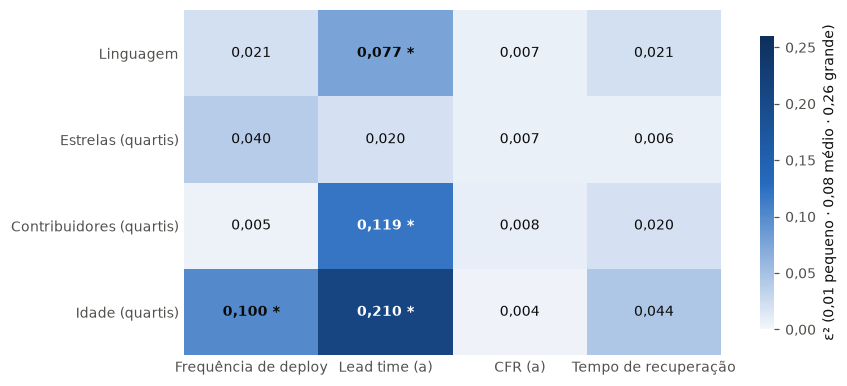

In [4]:
TEXTO, TEXTO_2, GRADE = '#0b0b0b', '#52514e', '#e4e3df'
CORES = ['#256abf', '#d26a2e']
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'font.size': 9,
    'axes.edgecolor': TEXTO_2, 'axes.labelcolor': TEXTO, 'text.color': TEXTO,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})
from matplotlib.colors import LinearSegmentedColormap

matriz = testes.pivot(index='fator', columns='metrica', values='tamanho_efeito').loc[list(FATORES), [m[0] for m in METRICAS.values()]]
signif = testes.pivot(index='fator', columns='metrica', values='significativo_holm').loc[matriz.index, matriz.columns]
mapa = LinearSegmentedColormap.from_list('azul', ['#f4f7fb', '#256abf', '#0d2f5c'])

fig, ax = plt.subplots(figsize=(7.6, 3.4), layout='constrained')
im = ax.imshow(matriz.to_numpy(), cmap=mapa, vmin=0, vmax=0.26, aspect='auto')
ax.grid(False)
ax.set_xticks(range(matriz.shape[1]), matriz.columns)
ax.set_yticks(range(matriz.shape[0]), matriz.index)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.iat[i, j]
        rotulo = f'{v:.3f}'.replace('.', ',') + (' *' if signif.iat[i, j] else '')
        ax.text(j, i, rotulo, ha='center', va='center', fontsize=9,
                color='white' if v > 0.11 else TEXTO, fontweight='bold' if signif.iat[i, j] else 'normal')
barra = fig.colorbar(im, ax=ax, shrink=0.85)
barra.set_label('ε² (0,01 pequeno · 0,08 médio · 0,26 grande)')
barra.ax.yaxis.set_major_formatter(lambda v, _: f'{v:.2f}'.replace('.', ','))
barra.outline.set_visible(False)
fig.savefig(FIGURAS / 'rq06_tamanho_efeito.png')
plt.show()

## Distribuições dos resultados significativos

Violinos por grupo para cada associação que sobreviveu à correção de Holm. Como os valores vão de minutos a anos, a densidade é estimada sobre o log10 da métrica e o eixo mostra os valores originais; a linha preta é a mediana e as cinzas, Q1 e Q3. Entre parênteses, o número de repositórios do grupo; † marca grupos com menos de 20.

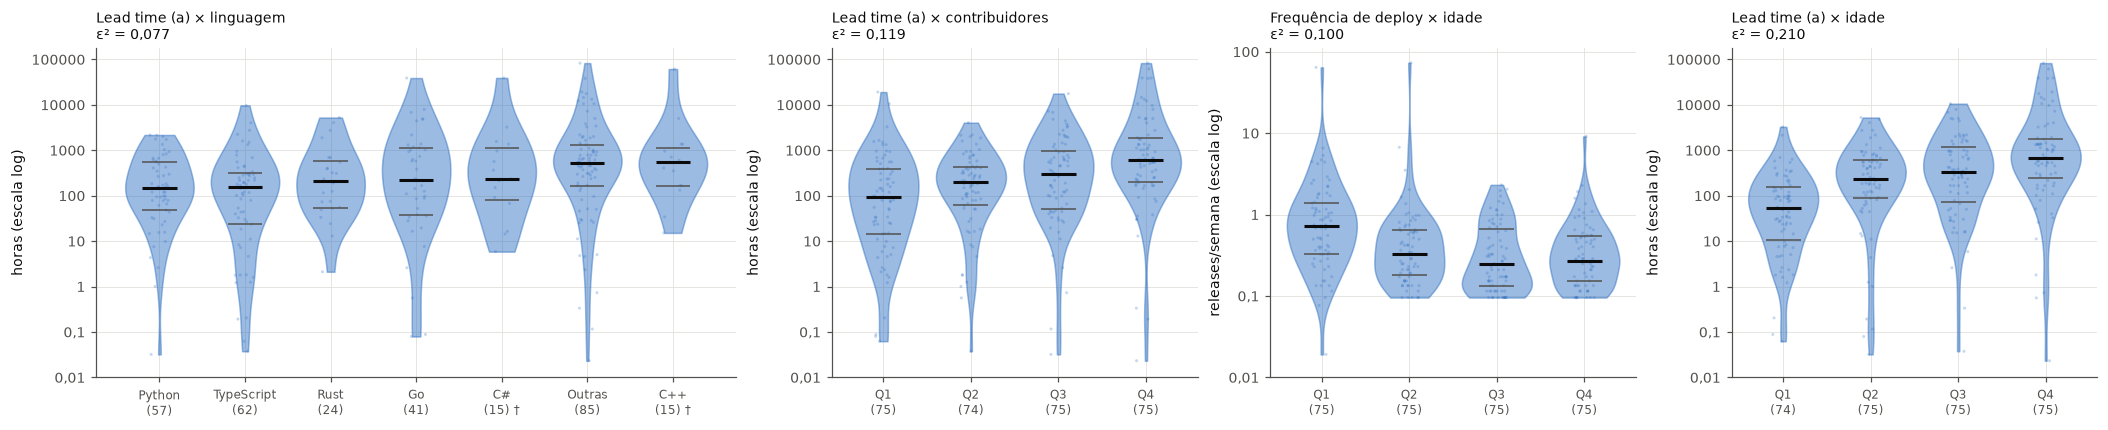

In [5]:
sig = testes[testes['significativo_holm']]
coluna_por_rotulo = {v[0]: (k, v[1]) for k, v in METRICAS.items()}
larguras = [len(pd.unique(FATORES[f].dropna())) for f in sig['fator']]
fig, eixos = plt.subplots(1, len(sig), figsize=(0.75 * sum(larguras) + 1.2 * len(sig), 3.8),
                          layout='constrained', squeeze=False, gridspec_kw={'width_ratios': larguras})
for ax, (_, linha) in zip(eixos[0], sig.iterrows()):
    coluna, unidade = coluna_por_rotulo[linha['metrica']]
    grupos = FATORES[linha['fator']]
    ordem_grupos = sorted(pd.unique(grupos.dropna()))
    if linha['fator'] == 'Linguagem':
        ordem_grupos = sorted(ordem_grupos, key=lambda g: df.loc[grupos == g, coluna].median())
    dados = [df.loc[(grupos == g) & (df[coluna] > 0), coluna].to_numpy() for g in ordem_grupos]
    logs = [np.log10(v) for v in dados]
    partes = ax.violinplot(logs, widths=0.8, showmedians=True, showextrema=False,
                           quantiles=[[0.25, 0.75]] * len(logs))
    for corpo in partes['bodies']:
        corpo.set_facecolor(CORES[0]); corpo.set_edgecolor(CORES[0]); corpo.set_alpha(0.45)
    partes['cmedians'].set_color(TEXTO); partes['cmedians'].set_linewidth(2)
    partes['cquantiles'].set_color(TEXTO_2); partes['cquantiles'].set_linewidth(1)
    rng = np.random.default_rng(42)
    for i, serie in enumerate(logs, start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(serie)), serie, s=4, alpha=0.25,
                   color=CORES[0], edgecolors='none', rasterized=True)
    expoentes = range(int(np.floor(min(map(np.min, logs)))), int(np.ceil(max(map(np.max, logs)))) + 1)
    ax.set_yticks(list(expoentes), [f'{10.0 ** e:g}'.replace('.', ',') for e in expoentes])
    rotulos = [f'{g}\n({len(v)})' + (' †' if len(v) < MIN_GRUPO else '') for g, v in zip(ordem_grupos, dados)]
    ax.set_xticks(range(1, len(ordem_grupos) + 1), rotulos, fontsize=8)
    ax.set_title(f"{linha['metrica']} × {linha['fator'].split(' (')[0].lower()}\nε² = {linha['tamanho_efeito']:.3f}".replace('.', ','), fontsize=9, loc='left')
    ax.set_ylabel(f'{unidade} (escala log)')
fig.savefig(FIGURAS / 'rq06_significativos.png')
plt.show()